In [1]:
# Step 1: Import Necessary Libraries
import os
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from nilearn import image, plotting, masking, datasets
from nilearn.input_data import NiftiMasker
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LassoCV
from sklearn.feature_selection import SelectFromModel
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score 
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

C:\Users\user\AppData\Local\Temp\ipykernel_17800\1298057760.py:7: DeprecationWarning: The import path 'nilearn.input_data' is deprecated in version 0.9. Importing from 'nilearn.input_data' will be possible at least until release 0.13.0. Please import from 'nilearn.maskers' instead.
  from nilearn.input_data import NiftiMasker


## Reading the ROIs **(MEAN)** to perform the experiments.

In [2]:
#### 1. Loading the Inferior Frontal Gyrus dataset in np format.
cmd1 = np.load("../../Data_Mask-ROI/1-Inferior_Frontal_Gyrus/control_mean_pars_triangularis.npz")
ndmd1 = np.load("../../Data_Mask-ROI/1-Inferior_Frontal_Gyrus/non_dyslexic_mean_pars_triangularis.npz")
control_mean_data1 = cmd1["control_mean_data1"]
non_dyslexic_mean_data1=ndmd1["non_dyslexic_mean_data1"]
cmd2 = np.load("../../Data_Mask-ROI/1-Inferior_Frontal_Gyrus/control_mean_pars_opercularis.npz")
ndmd2 = np.load("../../Data_Mask-ROI/1-Inferior_Frontal_Gyrus/non_dyslexic_mean_pars_opercularis.npz")
control_mean_data2 = cmd2["control_mean_data2"]
non_dyslexic_mean_data2=ndmd2["non_dyslexic_mean_data2"]
####
#### 2. Loading the Superior Temporal Gyrus dataset in np format.
cmd3 = np.load("../../Data_Mask-ROI/2-Superior_Temporal_Gyrus/control_mean_anterior_division.npz")
ndmd3 = np.load("../../Data_Mask-ROI/2-Superior_Temporal_Gyrus/non_dyslexic_mean_anterior_division.npz")
control_mean_data3 = cmd3["control_mean_data1"]
non_dyslexic_mean_data3=ndmd3["non_dyslexic_mean_data1"]
####
#### 3. Loading the Middle Temporal Gyrus dataset in np format.
cmd4 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/control_mean_anterior_division.npz")
ndmd4 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/non_dyslexic_mean_anterior_division.npz")
control_mean_data4 = cmd4["control_mean_data1"]
non_dyslexic_mean_data4=ndmd4["non_dyslexic_mean_data1"]
cmd5 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/control_mean_posterior_division.npz")
ndmd5 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/non_dyslexic_mean_posterior_division.npz")
control_mean_data5 = cmd5["control_mean_data2"]
non_dyslexic_mean_data5=ndmd5["non_dyslexic_mean_data2"]
cmd6 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/control_mean_temporooccipital_part.npz")
ndmd6 = np.load("../../Data_Mask-ROI/3-Middle_Temporal_Gyrus/non_dyslexic_mean_temporooccipital_part.npz")
control_mean_data6 = cmd6["control_mean_data3"]
non_dyslexic_mean_data6=ndmd6["non_dyslexic_mean_data3"]
####
#### 4. Loading the Inferior Temporal Gyrus dataset in np format.
cmd7 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/control_mean_anterior_division.npz")
ndmd7 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/non_dyslexic_mean_anterior_division.npz")
control_mean_data7 = cmd7["control_mean_data1"]
non_dyslexic_mean_data7=ndmd7["non_dyslexic_mean_data1"]
cmd8 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/control_mean_posterior_division.npz")
ndmd8 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/non_dyslexic_mean_posterior_division.npz")
control_mean_data8 = cmd8["control_mean_data2"]
non_dyslexic_mean_data8=ndmd8["non_dyslexic_mean_data2"]
cmd9 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/control_mean_temporooccipital_part.npz")
ndmd9 = np.load("../../Data_Mask-ROI/4-Inferior_Temporal_Gyrus/non_dyslexic_mean_temporooccipital_part.npz")
control_mean_data9 = cmd9["control_mean_data3"]
non_dyslexic_mean_data9=ndmd9["non_dyslexic_mean_data3"]
####
#### 5. Loading the Supramarginal Gyrus dataset in np format.
cmd10 = np.load("../../Data_Mask-ROI/5-Supramarginal_Gyrus/control_mean_anterior_division.npz")
ndmd10 = np.load("../../Data_Mask-ROI/5-Supramarginal_Gyrus/non_dyslexic_mean_anterior_division.npz")
control_mean_data10 = cmd10["control_mean_data1"]
non_dyslexic_mean_data10=ndmd10["non_dyslexic_mean_data1"]
cmd11 = np.load("../../Data_Mask-ROI/5-Supramarginal_Gyrus/control_mean_posterior_division.npz")
ndmd11 = np.load("../../Data_Mask-ROI/5-Supramarginal_Gyrus/non_dyslexic_mean_posterior_division.npz")
control_mean_data11 = cmd11["control_mean_data2"]
non_dyslexic_mean_data11=ndmd11["non_dyslexic_mean_data2"]
####
#### 6. Loading the Angular Gyrus dataset in np format.
cmd12 = np.load("../../Data_Mask-ROI/6-Angular_Gyrus/control_mean_angular_gyrus.npz")
ndmd12 = np.load("../../Data_Mask-ROI/6-Angular_Gyrus/non_dyslexic_mean_angular_gyrus.npz")
control_mean_data12 = cmd12["control_mean_data1"]
non_dyslexic_mean_data12=ndmd12["non_dyslexic_mean_data1"]
####
#### 7. Loading the Temporal Fusiform Cortex dataset in np format.
cmd13 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/control_mean_anterior_division.npz")
ndmd13 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/non_dyslexic_mean_anterior_division.npz")
control_mean_data13 = cmd13["control_mean_data1"]
non_dyslexic_mean_data13=ndmd13["non_dyslexic_mean_data1"]
cmd14 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/control_mean_posterior_division.npz")
ndmd14 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/non_dyslexic_mean_posterior_division.npz")
control_mean_data14 = cmd14["control_mean_data2"]
non_dyslexic_mean_data14=ndmd14["non_dyslexic_mean_data2"]
cmd15 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/control_mean_temporooccipital_part.npz")
ndmd15 = np.load("../../Data_Mask-ROI/7-Temporal_Fusiform_Cortex/non_dyslexic_mean_temporooccipital_part.npz")
control_mean_data15 = cmd15["control_mean_data3"]
non_dyslexic_mean_data15=ndmd15["non_dyslexic_mean_data3"]
####
#### 8. Loading the Occipital Fusiform Gyrus dataset in np format.
cmd16 = np.load("../../Data_Mask-ROI/8-Occipital_Fusiform_Gyrus/control_mean_occipital_fusiform_gyrus.npz")
ndmd16 = np.load("../../Data_Mask-ROI/8-Occipital_Fusiform_Gyrus/non_dyslexic_mean_occipital_fusiform_gyrus.npz")
control_mean_data16 = cmd16["control_mean_data1"]
non_dyslexic_mean_data16=ndmd16["non_dyslexic_mean_data1"]
####
print(len(control_mean_data1))
print(len(non_dyslexic_mean_data1))
print("1.1 Inferior Frontal Gyrus: Shape Control_1",control_mean_data1[0].shape)
print("1.1 Inferior Frontal Gyrus: Shape Non_Dyslexic_1",non_dyslexic_mean_data1[0].shape)
print(len(control_mean_data2))
print(len(non_dyslexic_mean_data2))
print("1.2 Inferior Frontal Gyrus: Shape Control_2",control_mean_data2[0].shape)
print("1.2 Inferior Frontal Gyrus: Shape Non_Dyslexic_2",non_dyslexic_mean_data2[0].shape)

print(len(control_mean_data3))
print(len(non_dyslexic_mean_data3))
print("2.1 Superior Temporal Gyrus: Shape Control_3",control_mean_data3[0].shape)
print("2.1 Superior Temporal Gyrus: Shape Non_Dyslexic_3",non_dyslexic_mean_data3[0].shape)

print(len(control_mean_data4))
print(len(non_dyslexic_mean_data4))
print("3.1 Middle Temporal Gyrus: Shape Control_4",control_mean_data4[0].shape)
print("3.1 Middle Temporal Gyrus: Shape Non_Dyslexic_4",non_dyslexic_mean_data4[0].shape)
print(len(control_mean_data5))
print(len(non_dyslexic_mean_data5))
print("3.2 Middle Temporal Gyrus: Shape Control_5",control_mean_data5[0].shape)
print("3.2 Middle Temporal Gyrus: Shape Non_Dyslexic_5",non_dyslexic_mean_data5[0].shape)
print(len(control_mean_data6))
print(len(non_dyslexic_mean_data6))
print("3.3 Middle Temporal Gyrus: Shape Control_6",control_mean_data6[0].shape)
print("3.3 Middle Temporal Gyrus: Shape Non_Dyslexic_6",non_dyslexic_mean_data6[0].shape)

print(len(control_mean_data7))
print(len(non_dyslexic_mean_data7))
print("4.1 Inferior Temporal Gyrus: Shape Control_7",control_mean_data7[0].shape)
print("4.1 Inferior Temporal Gyrus: Shape Non_Dyslexic_7",non_dyslexic_mean_data7[0].shape)
print(len(control_mean_data8))
print(len(non_dyslexic_mean_data8))
print("4.2 Inferior Temporal Gyrus: Shape Control_8",control_mean_data8[0].shape)
print("4.2 Inferior Temporal Gyrus: Shape Non_Dyslexic_8",non_dyslexic_mean_data8[0].shape)
print(len(control_mean_data9))
print(len(non_dyslexic_mean_data9))
print("4.3 Inferior Temporal Gyrus: Shape Control_9",control_mean_data9[0].shape)
print("4.3 Inferior Temporal Gyrus: Shape Non_Dyslexic_9",non_dyslexic_mean_data9[0].shape)

print(len(control_mean_data10))
print(len(non_dyslexic_mean_data10))
print("5.1 Supramarginal Gyrus: Shape Control_10",control_mean_data10[0].shape)
print("5.1 Supramarginal Gyrus: Shape Non_Dyslexic_10",non_dyslexic_mean_data10[0].shape)
print(len(control_mean_data11))
print(len(non_dyslexic_mean_data11))
print("5.2 Supramarginal Gyrus: Shape Control_11",control_mean_data11[0].shape)
print("5.2 Supramarginal Gyrus: Shape Non_Dyslexic_11",non_dyslexic_mean_data11[0].shape)

print(len(control_mean_data12))
print(len(non_dyslexic_mean_data12))
print("6.1 Angular Gyrus: Shape Control_12",control_mean_data12[0].shape)
print("6.1 Angular Gyrus: Shape Non_Dyslexic_12",non_dyslexic_mean_data12[0].shape)

print(len(control_mean_data13))
print(len(non_dyslexic_mean_data13))
print("7.1 Temporal Fusiform Cortex: Shape Control_13",control_mean_data13[0].shape)
print("7.1 Temporal Fusiform Cortex: Shape Non_Dyslexic_13",non_dyslexic_mean_data13[0].shape)
print(len(control_mean_data14))
print(len(non_dyslexic_mean_data14))
print("7.2 Temporal Fusiform Cortex: Shape Control_14",control_mean_data14[0].shape)
print("7.2 Temporal Fusiform Cortex: Shape Non_Dyslexic_14",non_dyslexic_mean_data14[0].shape)
print(len(control_mean_data15))
print(len(non_dyslexic_mean_data15))
print("7.3 Temporal Fusiform Cortex: Shape Control_15",control_mean_data15[0].shape)
print("7.3 Temporal Fusiform Cortex: Shape Non_Dyslexic_15",non_dyslexic_mean_data15[0].shape)

print(len(control_mean_data16))
print(len(non_dyslexic_mean_data16))
print("8.1 Occipital Fusiform Gyrus: Shape Control_16",control_mean_data16[0].shape)
print("8.1 Occipital Fusiform Gyrus: Shape Non_Dyslexic_16",non_dyslexic_mean_data16[0].shape)


80
80
1.1 Inferior Frontal Gyrus: Shape Control_1 (2377,)
1.1 Inferior Frontal Gyrus: Shape Non_Dyslexic_1 (2377,)
80
80
1.2 Inferior Frontal Gyrus: Shape Control_2 (3846,)
1.2 Inferior Frontal Gyrus: Shape Non_Dyslexic_2 (3846,)
80
80
2.1 Superior Temporal Gyrus: Shape Control_3 (1096,)
2.1 Superior Temporal Gyrus: Shape Non_Dyslexic_3 (1096,)
80
80
3.1 Middle Temporal Gyrus: Shape Control_4 (1979,)
3.1 Middle Temporal Gyrus: Shape Non_Dyslexic_4 (1979,)
80
80
3.2 Middle Temporal Gyrus: Shape Control_5 (8826,)
3.2 Middle Temporal Gyrus: Shape Non_Dyslexic_5 (8826,)
80
80
3.3 Middle Temporal Gyrus: Shape Control_6 (6190,)
3.3 Middle Temporal Gyrus: Shape Non_Dyslexic_6 (6190,)
80
80
4.1 Inferior Temporal Gyrus: Shape Control_7 (1665,)
4.1 Inferior Temporal Gyrus: Shape Non_Dyslexic_7 (1665,)
80
80
4.2 Inferior Temporal Gyrus: Shape Control_8 (4262,)
4.2 Inferior Temporal Gyrus: Shape Non_Dyslexic_8 (4262,)
80
80
4.3 Inferior Temporal Gyrus: Shape Control_9 (4819,)
4.3 Inferior Temporal

## Combining all the ROIs into a single dataset <i><b>(HORIZONTALLY)</b></i> to perform the experiments.
<b>Before the Feature Selection:- Row=80+80=160; Column=67687 (All the Columns of all the ROIs)<br>After Feature Selection: Row=80+80=160; Column=25267</b>

#### <B><span style="font-size:25px; color:RED">CODE EXPLANATION:</span> <span style="background-color:yellow"><font color='GREEN'>Just to explain how indices from the Feature<br><br>Sets of the brain regions are selected based on their IMPORTANCE</B></span></font>

In [75]:
import numpy as np
# Say this is one Feature set
ff=np.array([12, 4, 12, 33, 51, 17])
# Say this is the 'IMPORTANCE' of the Feature set
imp = np.array([6, 8, 3, 9, 5, 7])

# Get the 'IMPORTANCE' srted in descending way
descending_indices = np.argsort(imp)[::-1]

print("Original array:", ff)
print("Importance array:", imp)
print("Indices for descending sort:", descending_indices)
# Output: Indices for descending sort: [3 1 5 0 4 2]

# Just for Understanding purpose:-
# Displaying the elements in the Feature Set 'ff' in descending order using the indices of 'imp' as the basis of Sorting
sorted_descending = ff[descending_indices]
print("Array sorted in descending order:", sorted_descending)

# Now selecting the features from the Feature Set 'ff' based on it's IMPORTANCE ie 'imp' 
for k in range(1, 6+1):
    selected_indices = descending_indices[:k]
    # print(selected_indices)
    print(ff[selected_indices])

Original array: [12  4 12 33 51 17]
Importance array: [6 8 3 9 5 7]
Indices for descending sort: [3 1 5 0 4 2]
Array sorted in descending order: [33  4 17 12 51 12]
[33]
[33  4]
[33  4 17]
[33  4 17 12]
[33  4 17 12 51]
[33  4 17 12 51 12]


In [ ]:
# Create 8 feature sets with different feature dimensions
np.random.seed(42)
subjects = 160
dyslexic = 80
control = 80
labels = np.array([0] * dyslexic + [1] * control)  # 0 = Dyslexic, 1 = Control
feature_dims = [30, 40, 35, 50, 45, 38, 42, 36]
feature_sets = [np.random.rand(subjects, dim) for dim in feature_dims]
print(len(feature_sets))
print(feature_sets[0].shape)
print(feature_sets[7].shape)
print(feature_sets[0][159].shape)
print(feature_sets[0][159][29])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(feature_sets[0])
y = labels.copy()
    
# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)
    
# Train Random Forest and get feature importances
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
importances = rf.feature_importances_
ranked_indices = np.argsort(importances)[::-1]

# print(feature_sets[0].shape[1])
# print(importances)
# print(importances.shape)
print(ranked_indices)
# print(ranked_indices.shape)
scaler = StandardScaler()
#X_train = scaler.fit_transform(feature_sets[0])
for k in range(1, feature_sets[0].shape[1] + 1):
    selected_indices = ranked_indices[:k]
    print("KK",k)
    print("SEL_IN",selected_indices)
    # print(selected_indices.shape)
    print(feature_sets[0][:, selected_indices])


In [85]:
import numpy as np
array2d_a = np.array([[1, 2], [3, 4],[5, 6], [7, 8]])
array2d_b = np.array([[5, 6], [7, 8],[9, 10], [11, 12]])
array2d_c = np.array([[9, 10], [11, 12],[13, 14], [15, 16]])
array2d_d = np.array([[13, 14], [15, 16],[17, 18], [19, 20]])
result_2d = [array2d_a, array2d_b,array2d_c, array2d_d]
#print(f"2D Result:\n{result_2d}")
print(type(result_2d))
print(type(result_2d[0]))
print(len(result_2d))
print(result_2d[0])
print(result_2d[0].shape)
print(result_2d[3].shape)
print(result_2d[0][0].shape)
print(result_2d[0][2,1])


<class 'list'>
<class 'numpy.ndarray'>
4
[[1 2]
 [3 4]
 [5 6]
 [7 8]]
(4, 2)
(4, 2)
(2,)
6


In [95]:
subjects = 160
dyslexic = 80
control = 80

# Region 1: 50 features
region1_dyslexic = np.random.rand(dyslexic, 50)
region1_control = np.random.rand(control, 50)
region1=np.vstack([region1_dyslexic, region1_control])
# Region 2: 60 features
region2_dyslexic = np.random.rand(dyslexic, 60)
region2_control = np.random.rand(control, 60)
region2=np.vstack([region2_dyslexic, region2_control])
# Region 3: 40 features
region3_dyslexic = np.random.rand(dyslexic, 40)
region3_control = np.random.rand(control, 40)
region3=np.vstack([region3_dyslexic, region3_control])
print(region1.shape)
print(region2.shape)
print(region3.shape)
# Combine all feature sets horizontally
X_full = [region1, region2, region3]
print(len(X_full))
print(type(X_full))
print(type(X_full[0]))
print(X_full[0].shape)
print(X_full[1].shape)
print(X_full[0][0].shape)
print(X_full[0][159].shape)
print(X_full[1][0].shape)
print(X_full[1][159].shape)
print(X_full[0][0][0])
print(X_full[0][0][49])


(160, 50)
(160, 60)
(160, 40)
3
<class 'list'>
<class 'numpy.ndarray'>
(160, 50)
(160, 60)
(50,)
(50,)
(60,)
(60,)
0.7379629731331885
0.6676036917339434


## <font color='red'><span style="background-color:yellow"><B>END of CODE Explanation</B></span></font>

#### <span style="font-size:25px; background-color:yellow; color:green">PREPROCESSING DATASET</span> <span style="font-size:21px">Getting the dataset ready:-</span><BR><BR>First, we have to combine the feature sets of dyslexic and non-dyslexic of each region <b><i>Vertically</i></b>, i.e., <span style="background-color:green;color:red">80+80=160 Rows</span>. FINALLY, we combine all feature sets of all the Regions <b><i>Horizontally</i></b> <span style="background-color:green;color:red">160 Rows and 25267 column</span>

In [26]:
np.random.seed(42)
subjects = 160
dyslexic = 80
non_dyslexic = 80
# 0 = Dyslexic, 1 = Non_Dyslexic
labels = np.array([0] * dyslexic + [1] * non_dyslexic)  # 0 = Dyslexic, 1 = Non_Dyslexic

# First we have to combine the feature sets of dyslexic and non-dyslexic 
# of each region Vertically
# Region 1: 
region1=np.vstack([control_mean_data1, non_dyslexic_mean_data1])
# Region 2: 
region2=np.vstack([control_mean_data2, non_dyslexic_mean_data2])
# Region 3: 
region3=np.vstack([control_mean_data3, non_dyslexic_mean_data3])
# Region 4: 
region4=np.vstack([control_mean_data4, non_dyslexic_mean_data4])
# Region 5: 
region5=np.vstack([control_mean_data5, non_dyslexic_mean_data5])
# Region 6: 
region6=np.vstack([control_mean_data6, non_dyslexic_mean_data6])
# Region 7: 
region7=np.vstack([control_mean_data7, non_dyslexic_mean_data7])
# Region 8: 
region8=np.vstack([control_mean_data8, non_dyslexic_mean_data8])
# Region 9: 
region9=np.vstack([control_mean_data9, non_dyslexic_mean_data9])
# Region 10: 
region10=np.vstack([control_mean_data10, non_dyslexic_mean_data10])
# Region 11: 
region11=np.vstack([control_mean_data11, non_dyslexic_mean_data11])
# Region 12: 
region12=np.vstack([control_mean_data12, non_dyslexic_mean_data12])
# Region 13: 
region13=np.vstack([control_mean_data13, non_dyslexic_mean_data13])
# Region 14: 
region14=np.vstack([control_mean_data14, non_dyslexic_mean_data14])
# Region 15: 
region15=np.vstack([control_mean_data15, non_dyslexic_mean_data15])
# Region 16: 
region16=np.vstack([control_mean_data16, non_dyslexic_mean_data16])

# FINALLY, we combine all feature sets of all the Regions horizontally

feature_sets = [region1, region2, region3, region4, region5, region6, region7, region8, region9, region10, region11, region12, region13, region14, region15, region16]
print(len(feature_sets))
print(feature_sets[0].shape)
print(feature_sets[0][0].shape)
print(feature_sets[2].shape)
print(feature_sets[14].shape)
print(feature_sets[15].shape)
print(feature_sets[0][159].shape)
print(feature_sets[0][159][2376])


16
(160, 2377)
(2377,)
(160, 1096)
(160, 5066)
(160, 4478)
(2377,)
1.8490492e-07


## Step-by-step incremental feature selection and classification evaluation
### Selecting Important Features Using Random Forest 

In our experimental study, first we find out the important features from each of the sixteen feature sets of the individual brain region, separately. That is, first we perform Feature Selection on each of the sixteen feature sets, using Random Forest. Then we use the "Importance Features" to perform the Incremental Feature Selection, and evaluate its performance on the test set during each incremental iteration. We store the number of selected features and the corresponding accuracy for each iteration. The incremental iteration is designed in such a way that the best features are always evaluated. We find out the maximum accuracy and store the corresponding number of selected features for later use. After all the iteration for all eight feature sets are over, we plot the results against the feature set of the individual brain regions to visualize which brain region has the best model performance and the most important features. Finally, we use these features stored earlier to finally retrain the model with these selected features.

In [5]:
# Step-by-step incremental feature selection and classification evaluation
region_results = []
selected_feature_indices = []

for i, region in enumerate(feature_sets):
    print("PROCESSING REGION ",(i+1),"\n")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(region)
    y = labels.copy()
    
    # Split into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)
    
    # Train Random Forest and get feature importances
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)
    importances = rf.feature_importances_
    ranked_indices = np.argsort(importances)[::-1]
    
    max_acc = 0
    best_n_features = 0
    accuracy_list = []

    # Perform incremental feature selection
    for k in range(1, region.shape[1] + 1):
        selected_indices = ranked_indices[:k]
        clf = RandomForestClassifier(n_estimators=100, random_state=42)
        clf.fit(X_train[:, selected_indices], y_train)
        y_pred = clf.predict(X_test[:, selected_indices])
        acc = accuracy_score(y_test, y_pred)
        accuracy_list.append(acc)

        if acc > max_acc:
            max_acc = acc
            best_n_features = k
    
    region_results.append({
        'region_index': i,
        'accuracies': accuracy_list,
        'max_accuracy': max_acc,
        'best_n_features': best_n_features,
        'best_indices': ranked_indices[:best_n_features]
    })
    selected_feature_indices.append(ranked_indices[:best_n_features])
    print("COMPLETED REGION ",(i+1),"\n")


PROCESSING REGION  1 

COMPLETED REGION  1 

PROCESSING REGION  2 

COMPLETED REGION  2 

PROCESSING REGION  3 

COMPLETED REGION  3 

PROCESSING REGION  4 

COMPLETED REGION  4 

PROCESSING REGION  5 

COMPLETED REGION  5 

PROCESSING REGION  6 

COMPLETED REGION  6 

PROCESSING REGION  7 

COMPLETED REGION  7 

PROCESSING REGION  8 

COMPLETED REGION  8 

PROCESSING REGION  9 

COMPLETED REGION  9 

PROCESSING REGION  10 

COMPLETED REGION  10 

PROCESSING REGION  11 

COMPLETED REGION  11 

PROCESSING REGION  12 

COMPLETED REGION  12 

PROCESSING REGION  13 

COMPLETED REGION  13 

PROCESSING REGION  14 

COMPLETED REGION  14 

PROCESSING REGION  15 

COMPLETED REGION  15 

PROCESSING REGION  16 

COMPLETED REGION  16 



In [7]:
# --- Saving 'region_results' to Pickle ---
output_pickle_file = 'region_results_RF.pkl' # .pkl is a common extension for pickle files
with open(output_pickle_file, 'wb') as f: # 'wb' for write binary
    pickle.dump(region_results, f)
print(f"Data successfully saved to {output_pickle_file}")

# # --- Loading 'region_results'  ---
# region_results=[]
# output_pickle_file = 'region_results_RF.pkl' # .pkl is a common extension for pickle files
# with open(output_pickle_file, 'rb') as f: # 'rb' for read binary 
#     region_results = pickle.load(f)
# print(f"\nData successfully loaded from {output_pickle_file}")
# print(type(region_results))


Data successfully saved to region_results_RF.pkl


#### Collect final features from all regions for retraining

In [8]:
# Collect final features from all regions for retraining
X_selected_all_regions = []
for region, result in zip(feature_sets, region_results):
    scaler = StandardScaler()
    region_scaled = scaler.fit_transform(region)
    X_selected_all_regions.append(region_scaled[:, result['best_indices']])

# Concatenate selected features from all regions
X_final = np.hstack(X_selected_all_regions)
X_train, X_test, y_train, y_test = train_test_split(X_final, labels, test_size=0.2, stratify=labels, random_state=42)

##### SAVING THE FINAL DATASET
np.save('X_final_RF.npy', X_final)

ll=control_mean_data1[0].shape[0]+control_mean_data2[0].shape[0]+control_mean_data3[0].shape[0]+control_mean_data4[0].shape[0]+control_mean_data5[0].shape[0]+control_mean_data6[0].shape[0]+control_mean_data7[0].shape[0]+control_mean_data8[0].shape[0]+control_mean_data9[0].shape[0]+control_mean_data10[0].shape[0]+control_mean_data11[0].shape[0]+control_mean_data12[0].shape[0]+control_mean_data13[0].shape[0]+control_mean_data14[0].shape[0]+control_mean_data15[0].shape[0]+control_mean_data16[0].shape[0]
print("Before Feature Selection Dataset:-", ll)
print("After Feature Selection Dataset:-",X_final.shape[1])

print("Total Training Data set:- ","Dataset:-", X_train.shape,"Label:-",y_train.shape)
print("Total Testing set:- ","Dataset:-",X_test.shape,"Label:-",y_test.shape)


Before Feature Selection Dataset:- 67687
After Feature Selection Dataset:- 25267
Total Training Data set:-  Dataset:- (128, 25267) Label:- (128,)
Total Testing set:-  Dataset:- (32, 25267) Label:- (32,)


#### <span style="font-family:Georgia; font-size:29px;color:red">#####<span style="background-color:yellow; color:green"><b><u>LOADING THE SAVED DATASET</b></u></span>#####</span>

In [3]:
np.random.seed(42)
subjects = 160
dyslexic = 80
non_dyslexic = 80
# 0 = Dyslexic, 1 = Non_Dyslexic
labels = np.array([0] * dyslexic + [1] * non_dyslexic)  # 0 = Dyslexic, 1 = Non_Dyslexic

# First we have to combine the feature sets of dyslexic and non-dyslexic 
# of each region Vertically
# Region 1: 
region1=np.vstack([control_mean_data1, non_dyslexic_mean_data1])
# Region 2: 
region2=np.vstack([control_mean_data2, non_dyslexic_mean_data2])
# Region 3: 
region3=np.vstack([control_mean_data3, non_dyslexic_mean_data3])
# Region 4: 
region4=np.vstack([control_mean_data4, non_dyslexic_mean_data4])
# Region 5: 
region5=np.vstack([control_mean_data5, non_dyslexic_mean_data5])
# Region 6: 
region6=np.vstack([control_mean_data6, non_dyslexic_mean_data6])
# Region 7: 
region7=np.vstack([control_mean_data7, non_dyslexic_mean_data7])
# Region 8: 
region8=np.vstack([control_mean_data8, non_dyslexic_mean_data8])
# Region 9: 
region9=np.vstack([control_mean_data9, non_dyslexic_mean_data9])
# Region 10: 
region10=np.vstack([control_mean_data10, non_dyslexic_mean_data10])
# Region 11: 
region11=np.vstack([control_mean_data11, non_dyslexic_mean_data11])
# Region 12: 
region12=np.vstack([control_mean_data12, non_dyslexic_mean_data12])
# Region 13: 
region13=np.vstack([control_mean_data13, non_dyslexic_mean_data13])
# Region 14: 
region14=np.vstack([control_mean_data14, non_dyslexic_mean_data14])
# Region 15: 
region15=np.vstack([control_mean_data15, non_dyslexic_mean_data15])
# Region 16: 
region16=np.vstack([control_mean_data16, non_dyslexic_mean_data16])

# FINALLY, we combine all feature sets of all the Regions horizontally

feature_sets = [region1, region2, region3, region4, region5, region6, region7, region8, region9, region10, region11, region12, region13, region14, region15, region16]
num_brain_regions=len(feature_sets)
print("Number of Brain Regions:",len(feature_sets))

total_features_across_regions_list = [] # To store individual N for each region
for i in range(num_brain_regions):
    num_original_features_i = feature_sets[i].shape[1]
    print(f"  Region {i} has {num_original_features_i} original features.")
    total_features_across_regions_list.append(num_original_features_i)


Number of Brain Regions: 16
  Region 0 has 2377 original features.
  Region 1 has 3846 original features.
  Region 2 has 1096 original features.
  Region 3 has 1979 original features.
  Region 4 has 8826 original features.
  Region 5 has 6190 original features.
  Region 6 has 1665 original features.
  Region 7 has 4262 original features.
  Region 8 has 4819 original features.
  Region 9 has 5153 original features.
  Region 10 has 4273 original features.
  Region 11 has 6557 original features.
  Region 12 has 1547 original features.
  Region 13 has 5553 original features.
  Region 14 has 5066 original features.
  Region 15 has 4478 original features.


In [4]:
##### LOADING THE FINAL DATASET

# --- Loading 'region_results'  ---
region_results=[]
output_pickle_file = 'region_results_RF.pkl' # .pkl is a common extension for pickle files
with open(output_pickle_file, 'rb') as f: # 'rb' for read binary 
    region_results = pickle.load(f)
print(f"\nData successfully loaded from {output_pickle_file}")
print(type(region_results))

# --- Loading dataset  ---
X_final = np.load('X_final_RF.npy')
X_train, X_test, y_train, y_test = train_test_split(X_final, labels, test_size=0.2, stratify=labels, random_state=42)
ll=control_mean_data1[0].shape[0]+control_mean_data2[0].shape[0]+control_mean_data3[0].shape[0]+control_mean_data4[0].shape[0]+control_mean_data5[0].shape[0]+control_mean_data6[0].shape[0]+control_mean_data7[0].shape[0]+control_mean_data8[0].shape[0]+control_mean_data9[0].shape[0]+control_mean_data10[0].shape[0]+control_mean_data11[0].shape[0]+control_mean_data12[0].shape[0]+control_mean_data13[0].shape[0]+control_mean_data14[0].shape[0]+control_mean_data15[0].shape[0]+control_mean_data16[0].shape[0]
print("Before Feature Selection Dataset:-", ll)
print("After Feature Selection Dataset:-",X_final.shape[1])
print("Total Training Data set:- ","Dataset:-", X_train.shape,"Label:-",y_train.shape)
print("Total Testing set:- ","Dataset:-",X_test.shape,"Label:-",y_test.shape)



Data successfully loaded from region_results_RF.pkl
<class 'list'>
Before Feature Selection Dataset:- 67687
After Feature Selection Dataset:- 25267
Total Training Data set:-  Dataset:- (128, 25267) Label:- (128,)
Total Testing set:-  Dataset:- (32, 25267) Label:- (32,)


## <span style="font-family: Georgia;"><b><u>Analysis of the feature selection</b></u></span>

<span style="font-family: Georgia; font-size:23px;"><b><u>Visual Interpretations {by Ploting}</b></u></span>
<b></b>

C:\Users\user\AppData\Local\Temp\ipykernel_17800\1525463609.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='region_index', y='max_accuracy', data=df, palette='viridis')


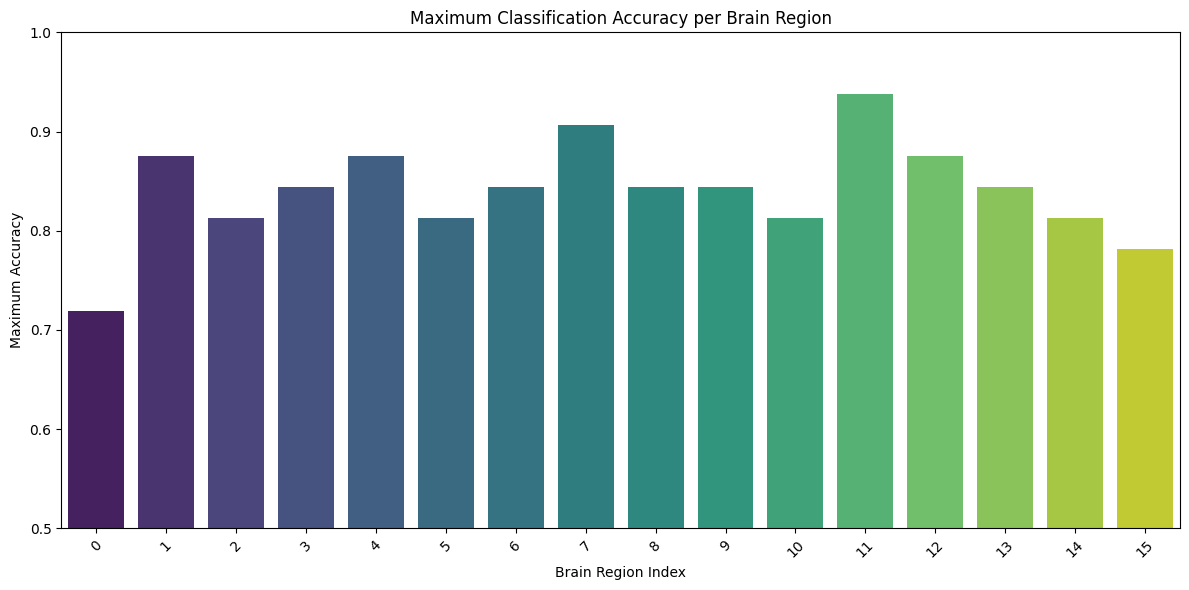

In [5]:
# --- Convert to Pandas DataFrame for Easier Analysis ---
df = pd.DataFrame(region_results)
# Dynamically add 'total_features_for_region' to the DataFrame
# Create a mapping from region_index to its total features
region_to_total_features_map = {i: feature_sets[i].shape[1] for i in range(num_brain_regions)}
df['total_features_for_region'] = df['region_index'].map(region_to_total_features_map)
df['best_n_features_percentage'] = (df['best_n_features'] / df['total_features_for_region']) * 100
# Plot 1: Max Accuracy per Brain Region
plt.figure(figsize=(12, 6))
sns.barplot(x='region_index', y='max_accuracy', data=df, palette='viridis')
plt.title('Maximum Classification Accuracy per Brain Region')
plt.xlabel('Brain Region Index')
plt.ylabel('Maximum Accuracy')
plt.ylim(0.5, 1.0) # Set y-axis limits for accuracy
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Max_Acc_per_Region).png", dpi=600)
plt.show() # Display plot

In [6]:
new_df1 = df[['region_index','max_accuracy']].copy() 
# Rename the columns in the new DataFrame
new_df1 = new_df1.rename(columns={'region_index':'Regions','max_accuracy':'Maximum Classification Accuracy per Brain Region'})
new_df1.to_excel('../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Max_Acc_per_Region).xlsx', index=False, engine='openpyxl')
display(new_df1.set_index('Regions'))

,Maximum Classification Accuracy per Brain Region
Regions,
0,0.71875
1,0.87500
2,0.81250
3,0.84375
4,0.87500
5,0.81250
6,0.84375
7,0.90625
8,0.84375


In [7]:
new_df2 = df[['region_index','total_features_for_region','best_n_features','best_n_features_percentage']].copy() 
# Rename the columns in the new DataFrame
new_df2 = new_df2.rename(columns={'region_index':'Regions','total_features_for_region': 'Number of Features', 'best_n_features': 'Number of Best Features','best_n_features_percentage':'Percentage of Features Selected'})
new_df2.to_excel('../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Total_vs_best_fea).xlsx', index=False, engine='openpyxl')
display(new_df2.set_index('Regions'))

,Number of Features,Number of Best Features,Percentage of Features Selected
Regions,,,
0,2377,685,28.817838
1,3846,739,19.214769
2,1096,344,31.386861
3,1979,1536,77.614957
4,8826,326,3.693632
5,6190,2082,33.634895
6,1665,1491,89.549550
7,4262,2878,67.526983
8,4819,1040,21.581241


In [8]:
new_df3 = df[['region_index','total_features_for_region','max_accuracy','best_n_features','best_n_features_percentage']].copy() 
new_df3['region_index'] += 1
# Rename the columns in the new DataFrame
new_df3 = new_df3.rename(columns={'region_index':'Regions','total_features_for_region': 'Number of Features' ,'max_accuracy':'Maximum Accuracy', 'best_n_features': 'Number of Best Features','best_n_features_percentage':'Percentage of Features Selected'})
# Save to Excel with 1-based regions
new_df3.to_excel('../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Total_vs_best_fea_with_Max_Acc).xlsx', index=False, engine='openpyxl')
display(new_df3.set_index('Regions'))

,Number of Features,Maximum Accuracy,Number of Best Features,Percentage of Features Selected
Regions,,,,
1,2377,0.71875,685,28.817838
2,3846,0.87500,739,19.214769
3,1096,0.81250,344,31.386861
4,1979,0.84375,1536,77.614957
5,8826,0.87500,326,3.693632
6,6190,0.81250,2082,33.634895
7,1665,0.84375,1491,89.549550
8,4262,0.90625,2878,67.526983
9,4819,0.84375,1040,21.581241


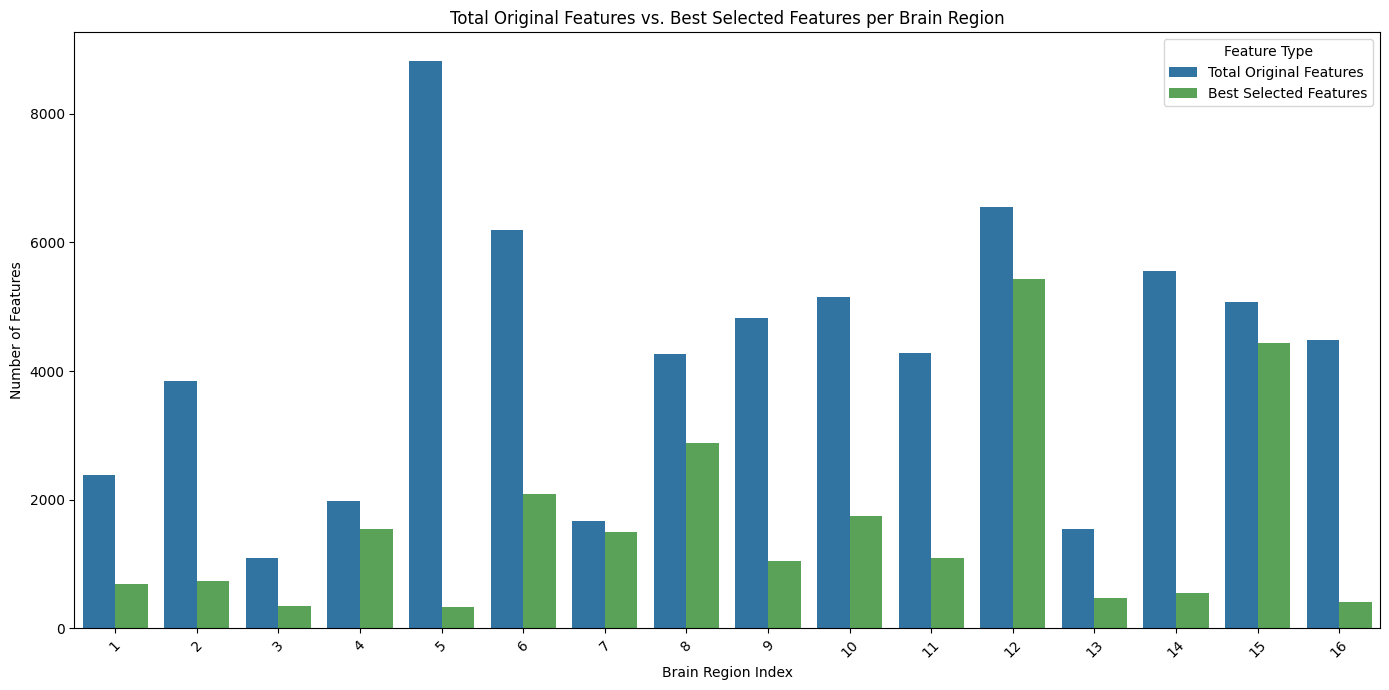

In [9]:
# PLOT 2: Total Features vs Best N Features per Region
plt.figure(figsize=(14, 7))
# Melt the DataFrame to easily plot 'Total_features_for_region' and 'Best_n_features' side-by-side
plot_df = df[['region_index', 'total_features_for_region', 'best_n_features']].melt(
    id_vars='region_index',
    var_name='Feature_Type',
    value_name='Count'
)
sns.barplot(x='region_index', y='Count', hue='Feature_Type', data=plot_df, palette={'total_features_for_region': '#1f77b4', 'best_n_features': '#4daf4a'})
plt.title('Total Original Features vs. Best Selected Features per Brain Region')
plt.xlabel('Brain Region Index')
plt.ylabel('Number of Features')

regions = sorted(df['region_index'])
plt.xticks(
    ticks=regions,                     # positions 0,1,2,...
    labels=(np.array(regions) + 1),    # labels 1,2,3,...
    rotation=45
)

handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, title='Feature Type', labels=['Total Original Features', 'Best Selected Features'])
plt.tight_layout()
plt.savefig("../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Total_vs_best_fea).png", dpi=600)
##plt.savefig("../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Yeah-Yeah).png", dpi=600)
plt.show()


C:\Users\user\AppData\Local\Temp\ipykernel_17800\2556858250.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='region_index', y='best_n_features_percentage', data=df, palette='cubehelix')


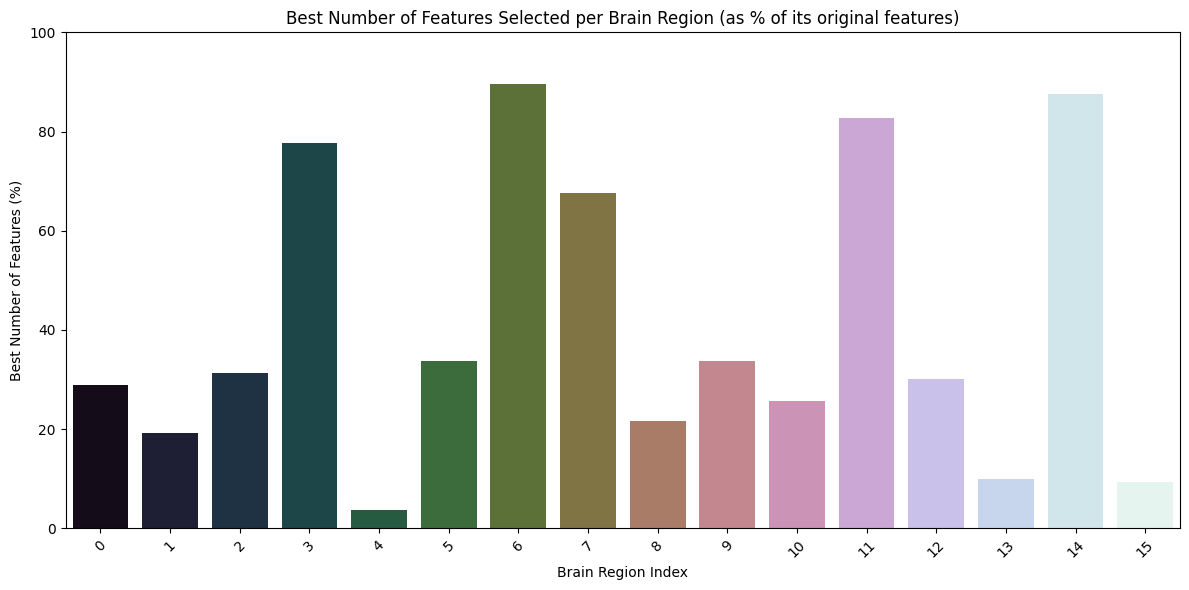

In [10]:
# Distribution of Best Number of Features
# df['best_n_features_percentage'] = (df['best_n_features'] / df['total_features_for_region']) * 100

# Plot 3: Best Number of Features per Brain Region (Bar Plot) - Now in Percentages relative to its own total
plt.figure(figsize=(12, 6))
sns.barplot(x='region_index', y='best_n_features_percentage', data=df, palette='cubehelix')
plt.title('Best Number of Features Selected per Brain Region (as % of its original features)')
plt.xlabel('Brain Region Index')
plt.ylabel('Best Number of Features (%)')
plt.ylim(0, 100) # Set y-axis limits for percentage
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../../Figure_Output/9-All_ROIs/Output_Mean/FE_SE_RF/RF_Fe_Se(Distr_best_n_fea).png", dpi=600)
plt.show() # Display plot


<span style="background-color:yellow; font-family:Georgia; font-size:29px;color:red">Sequential Feature Integration Based on Ranking</span>

<span style="background-color:yellow; font-family:Georgia; font-size:23px;color:red">Performing Ranking-Based Sequential Feature Integration using Classification Algorithm: Random Forest</span>

In [11]:
region_results_sorted = sorted(region_results, key=lambda x: x['max_accuracy'], reverse=True)
print(type(region_results_sorted))
print(len(region_results_sorted))
print(type(region_results_sorted[0]))
for key in region_results_sorted[0]:
    print(key)

sum=0
for i in range(16):
    ri = region_results_sorted[i]['region_index']
    m = region_results_sorted[i]['max_accuracy']
    print(f"({i}) Region {ri} -- Max Accuracy: {m}")
    sum=sum+m
avg_acc=round((sum/16)*100,2)
print("Average Accuracy=",avg_acc)


<class 'list'>
16
<class 'dict'>
region_index
accuracies
max_accuracy
best_n_features
best_indices
(0) Region 11 -- Max Accuracy: 0.9375
(1) Region 7 -- Max Accuracy: 0.90625
(2) Region 1 -- Max Accuracy: 0.875
(3) Region 4 -- Max Accuracy: 0.875
(4) Region 12 -- Max Accuracy: 0.875
(5) Region 3 -- Max Accuracy: 0.84375
(6) Region 6 -- Max Accuracy: 0.84375
(7) Region 8 -- Max Accuracy: 0.84375
(8) Region 9 -- Max Accuracy: 0.84375
(9) Region 13 -- Max Accuracy: 0.84375
(10) Region 2 -- Max Accuracy: 0.8125
(11) Region 5 -- Max Accuracy: 0.8125
(12) Region 10 -- Max Accuracy: 0.8125
(13) Region 14 -- Max Accuracy: 0.8125
(14) Region 15 -- Max Accuracy: 0.78125
(15) Region 0 -- Max Accuracy: 0.71875
Average Accuracy= 83.98


<span style="font-family:Times New Roman; font-size:23px;">Using Random Forest <span style="background-color:yellow; font-family:Georgia; font-size:25px;color:red">93.75%</span> accuracy is acquired</span>